In [ ]:
%pip install kagglehub
%pip install matplotlib
%pip install scikit-learn

In [14]:
import sys 
sys.path.insert(0,"workspace")
from src.data_leader import load_data
from src.mobilenet_transfer import build_transfer_model
from src.cnn_scratch import build_cnn_model
from src.mobilenet_finetuning import build_finetuning_model
from src.evaluate import evaluate_model
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

In [15]:
train_ds , val_ds , test_ds = load_data()

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.


===========================>  cnn_from_scratch  :

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 14s 50ms/step - accuracy: 0.7398 - loss: 0.6058 - precision: 0.8999 - recall: 0.7150 - val_accuracy: 0.9377 - val_loss: 0.1809 - val_precision: 0.9893 - val_recall: 0.9282
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9512 - loss: 0.1524 - precision: 0.9853 - recall: 0.9472 - val_accuracy: 0.9616 - val_loss: 0.1356 - val_precision: 0.9809 - val_recall: 0.9685
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.9439 - loss: 0.1571 - precision: 0.9805 - recall: 0.9421 - val_accuracy: 0.9645 - val_loss: 0.1245 - val_precision: 0.9846 - val_recall: 0.9685
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.9577 - loss: 0.1157 - precision: 0.9883 - recall: 0.9531 - val_accuracy: 0.9597 - val_loss: 0.1399 - val_precision: 0.9845 - val_recall: 0.9622
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.9724 - loss: 0.0754 - precision: 0.99

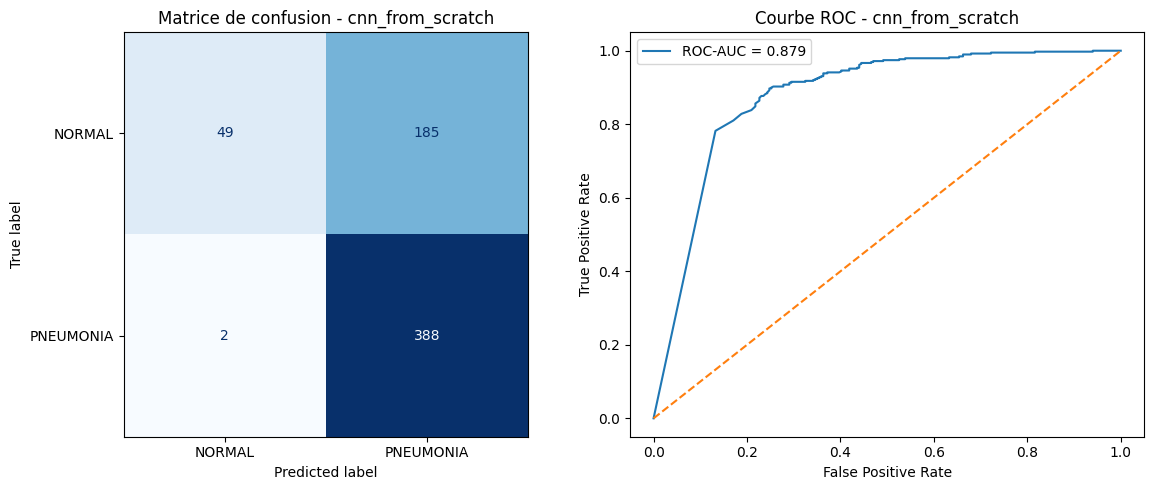

model sauvgarde sucessfull ! 
===========================>  transfer_learning  :

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.7226 - loss: 0.5267 - precision: 0.8728 - recall: 0.7181 - val_accuracy: 0.9482 - val_loss: 0.1811 - val_precision: 0.9648 - val_recall: 0.9673
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.9203 - loss: 0.2188 - precision: 0.9773 - recall: 0.9130 - val_accuracy: 0.9482 - val_loss: 0.1512 - val_precision: 0.9545 - val_recall: 0.9786
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9328 - loss: 0.1775 - precision: 0.9817 - recall: 0.9247 - val_accuracy: 0.9540 - val_loss: 0.1416 - val_precision: 0.9770 - val_recall: 0.9622
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.9449 - loss: 0.1487 - precision: 0.9847 - recall: 0.9393 - val_accuracy: 0.9597 - val_loss: 0.1309 - val_precision: 0.9772 - val_recall: 0.9698
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.9455 -

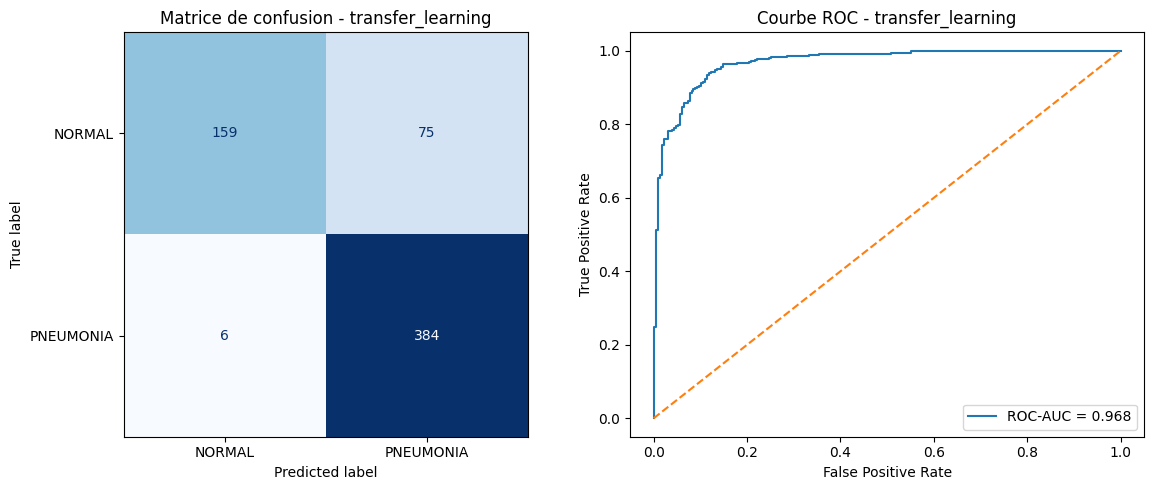

model sauvgarde sucessfull ! 
===========================>  fine_tuning  :

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 15s 65ms/step - accuracy: 0.6873 - loss: 0.5088 - precision: 0.9236 - recall: 0.6181 - val_accuracy: 0.8389 - val_loss: 0.3220 - val_precision: 0.8274 - val_recall: 0.9962
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - accuracy: 0.9007 - loss: 0.2285 - precision: 0.9847 - recall: 0.8780 - val_accuracy: 0.9080 - val_loss: 0.2337 - val_precision: 0.8984 - val_recall: 0.9912
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.9315 - loss: 0.1698 - precision: 0.9812 - recall: 0.9243 - val_accuracy: 0.9482 - val_loss: 0.1797 - val_precision: 0.9523 - val_recall: 0.9811
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.9498 - loss: 0.1338 - precision: 0.9872 - recall: 0.9439 - val_accuracy: 0.9530 - val_loss: 0.1546 - val_precision: 0.9782 - val_recall: 0.9597
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - accuracy: 0.9579 - loss:

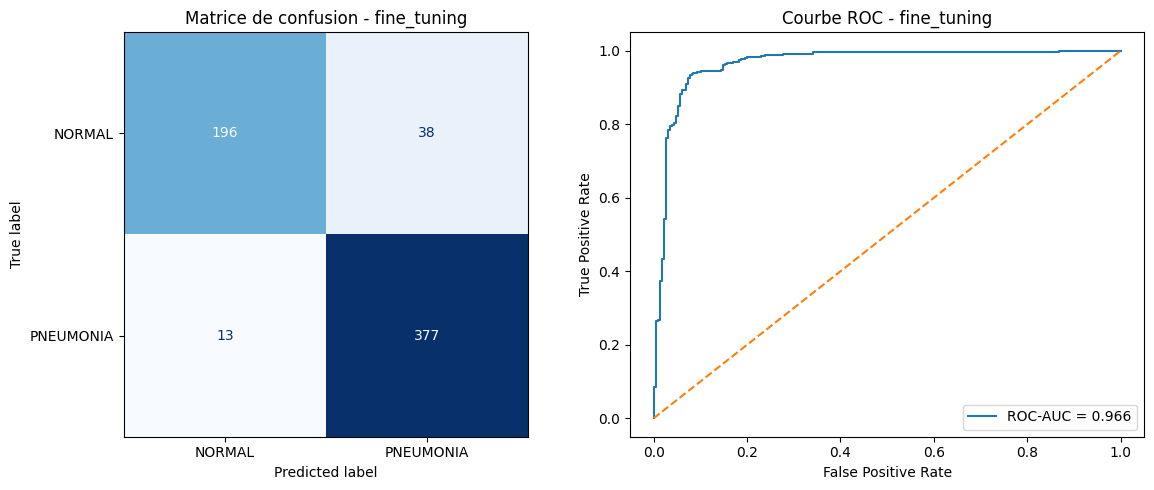

model sauvgarde sucessfull ! 


In [16]:
models = {
    "cnn_from_scratch" : build_cnn_model(),
    "transfer_learning" : build_transfer_model(),
    "fine_tuning" : build_finetuning_model()
}
evaluate = {

}
for name , model in models.items():
    print("===========================> " , name , " :\n")
    y_true = np.concatenate([
        labels.numpy().ravel() for images , labels in train_ds
    ])
    classes = np.unique(y_true)
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_true
    )
    classes_weights = {
        int(cls) : float(weight) for cls , weight in zip(classes , weights)
    }
    model.fit(train_ds,validation_data=val_ds , epochs=15 , class_weight=classes_weights)
    resultat = evaluate_model(model , test_ds , name)
    evaluate[name] = resultat
    model.save(f"{name}_model.keras")
    print("model sauvgarde sucessfull ! ")



In [12]:
print(evaluate)

{'cnn_from_scratch': {'accuracy': 0.780448717948718, 'precision': 0.7456310679611651, 'recall': 0.9846153846153847, 'f1_score': 0.8486187845303867, 'roc_auc': 0.9193896559281175, 'confusion_matrix': [[103, 131], [6, 384]]}, 'transfer_learning': {'accuracy': 0.8381410256410257, 'precision': 0.797938144329897, 'recall': 0.9923076923076923, 'f1_score': 0.8845714285714286, 'roc_auc': 0.9669515669515669, 'confusion_matrix': [[136, 98], [3, 387]]}, 'fine_tuning': {'accuracy': 0.8862179487179487, 'precision': 0.8584269662921349, 'recall': 0.9794871794871794, 'f1_score': 0.9149700598802395, 'roc_auc': 0.9568923953539339, 'confusion_matrix': [[171, 63], [8, 382]]}}
